# Gaussian process surrogates for Bayesian magnetotelluric inversion

Bayesian inversion gives what a single best-fit model cannot: the full set of Earth models that
explain the data, and how sure we can be about each layer. The price is the forward model.
Markov chain Monte Carlo (MCMC) needs hundreds of thousands of forward runs, which is fine for a
1D model (milliseconds) but impossible for 2D or 3D magnetotellurics (MT), where one run takes
minutes to hours.

This notebook studies the standard fix, a **Gaussian process (GP) surrogate** (kriging) of
the forward model, on a problem where the exact answer can still be computed. That lets us
measure exactly how much accuracy a surrogate loses and how many forward runs it saves.

The 1D forward model is cheap, so every surrogate result can be compared with a long
reference MCMC that uses the true model. **Cost is counted in forward-model calls**, which is
what matters when the model is expensive.

**Questions**
1. How many forward calls does a GP surrogate need to reproduce the true posterior?
2. Does it matter *where* the training runs are placed (fixed space-filling design against
   active learning)?
3. How do surrogates compare with the usual cheap alternative, a Gaussian (Laplace)
   approximation around the best fit, and with an exact two-stage scheme (delayed acceptance)?
4. Does it hold up on real data?

**Plan**
1. Setup and data
2. The problem: 1D MT forward model and Bayesian inversion
3. Why it is hard (four short demos)
4. Field data: EDA of 15 broadband MT stations
5. First-principles design: emulator, surrogate likelihood, active learning, samplers
6. Baselines
7. Experiments with a known answer (two synthetic cases)
8. Field station pb30c
9. Summary

## 1. Setup

Field data: 15 broadband MT stations (EDI files) from a survey near Paralana, South Australia,
acquired by the University of Adelaide in 2011 and distributed as example data with the open
source MTpy package. The files are downloaded from one pinned commit and checked by SHA-256.
See the MTpy repository for the terms of use.

In [1]:
import os, json, re, time, hashlib, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel, WhiteKernel

warnings.filterwarnings("ignore")
np.set_printoptions(precision=3, suppress=True)
FIG, DATA, RES = "figures", "data", "results"
for d_ in (FIG, DATA, RES):
    os.makedirs(d_, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
COL = {"reference": "#222222", "laplace": "#3b82c4", "lhs": "#e39b2d", "active": "#d64532", "da": "#7a1f14", "prior": "#bbbbbb"}
LAB = {"reference": "reference MCMC (true model)", "laplace": "Laplace (Gauss-Newton)",
       "lhs": "GP, fixed design (LHS)", "active": "GP, active learning (ours)", "da": "delayed acceptance (exact)"}
MU0 = 4e-7 * np.pi

def savefig(fig, name):
    fig.savefig(f"{FIG}/{name}.png", dpi=130, bbox_inches="tight")

In [2]:
MTPY = ("MTgeophysics/mtpy", "c4554ec6f67116878f004ffc2806215996529e6f", "examples/data/edi_files")
EDI_SHA = {
    "pb23c.edi": "b22ed6b39d10a3fa3a84eb064a8e777bcf6438cc4b7706b2299b4fa5454f0fc5",
    "pb25c.edi": "9ce843f8ef05bb30490e6458587e14a98b0b8366c2a20069f9eb891c4e9404cf",
    "pb27c.edi": "376ebed0c69a03dc8b42b949d1f502778ae0534d677a441278acb596754e4683",
    "pb29c.edi": "b717f171641de1f15ec06cddc47dae408481cf54e3eea3a3061104eae4e7d416",
    "pb30c.edi": "9ec4c2437767095d9637a70d16da756ca40d8504ed8d56848b52a4d54437c6d6",
    "pb32c.edi": "288630e3e9c6d38548dc7ad5283e7de427f3bde2056c610fc2815c1367745aff",
    "pb33c.edi": "a208eaa1d73bd2e45940d789dec0cf71c9eda2325cbbec3c636f30f52e7d6f19",
    "pb35c.edi": "b898ee404c312e5dc52e52160964cd06c7d7e3012fa9bcec290b507f7722a3a4",
    "pb37c.edi": "0a5a2a414188c358d3dded59e86487145ce60405518f3ddde72ef08648600d4e",
    "pb39c.edi": "0ceee4bea487627aecb3105eb0ef783b26e67284dfefa062d05b72894b1f9d7f",
    "pb40c.edi": "1486775a9e93774a8ab242f493383a9646271b95f7a93145370ab2d6341d9d8a",
    "pb41c.edi": "a0be8630f9fa1780951761237ae6044049a84c9431ae9a355acb904489448ceb",
    "pb42c.edi": "0dd30e33831e046cca5629e246143f6cd3f30e5309d7b005240397cc3194d4b6",
    "pb43c.edi": "d704fc722d3b491ca4c6e24f80016fb30a77ac789d6a0015f5d4cd89440ade20",
    "pb44c.edi": "1eb3d6b5df8114aca47891299993e095d064ef94cfecf9f1d987192038d6e95e",
}
manifest = {}
for fn, h in EDI_SHA.items():
    url = f"https://raw.githubusercontent.com/{MTPY[0]}/{MTPY[1]}/{MTPY[2]}/{fn}"
    dest = os.path.join(DATA, fn)
    if not os.path.exists(dest):
        urllib.request.urlretrieve(url, dest)
    dg = hashlib.sha256(open(dest, "rb").read()).hexdigest()
    assert dg == h, f"checksum mismatch for {fn}"
    manifest[fn] = dict(url=url, sha256=dg)
json.dump(manifest, open(f"{RES}/data_manifest.json", "w"), indent=1)
print(len(manifest), "EDI files verified")

15 EDI files verified


## 2. The problem

### 2.1 The 1D MT forward model

Natural electromagnetic fields induce currents in the Earth. At each frequency $f$ the ratio
of horizontal electric to magnetic field is the impedance $Z(f)$. Lower frequencies diffuse
deeper (skin depth $\delta \approx 503\sqrt{\rho/f}$ m), so the impedance across frequency is
a sounding of resistivity with depth.

For $n$ flat layers with resistivities $\rho_1,\dots,\rho_n$ and thicknesses
$h_1,\dots,h_{n-1}$ (the last layer is a half-space), the impedance follows from Wait's
recursion, from the bottom up:

$$
k_j = \sqrt{\frac{i\omega\mu_0}{\rho_j}}, \qquad Z^{(0)}_j = \frac{i\omega\mu_0}{k_j}, \qquad
Z_n = Z^{(0)}_n, \qquad
Z_j = Z^{(0)}_j\, \frac{Z_{j+1} + Z^{(0)}_j \tanh(k_j h_j)}{Z^{(0)}_j + Z_{j+1}\tanh(k_j h_j)},
$$

with $\omega = 2\pi f$. The data are the **apparent resistivity** and **phase** of $Z_1$:

$$
\rho_a(f) = \frac{|Z_1|^2}{\omega \mu_0}, \qquad \varphi(f) = \arg Z_1 .
$$

Over a uniform half-space $\rho_a = \rho$ and $\varphi = 45°$. Phases above $45°$ mean
resistivity decreasing with depth, below $45°$ increasing.

**Parameters** $\theta = (\log_{10}\rho_1, \dots, \log_{10}\rho_n, \log_{10}h_1, \dots, \log_{10}h_{n-1})$,
so $2n - 1$ unknowns. **Data** $d = (\log_{10}\rho_a(f_1..f_F), \varphi(f_1..f_F))$, so $2F$ numbers.

In [3]:
class Calls:
    """Counts forward-model calls (one call = one Earth model at all frequencies)."""
    n = 0

def mt1d(theta, freqs, nlay):
    theta = np.atleast_2d(theta)
    Calls.n += theta.shape[0]
    rho, h = 10.0 ** theta[:, :nlay], 10.0 ** theta[:, nlay:]
    w = 2 * np.pi * freqs[None, :]
    k = np.sqrt(1j * w[..., None] * MU0 / rho[:, None, :])
    Z0 = 1j * w[..., None] * MU0 / k
    Z = Z0[..., -1]
    for j in range(nlay - 2, -1, -1):
        t = np.tanh(k[..., j] * h[:, None, j])
        Z = Z0[..., j] * (Z + Z0[..., j] * t) / (Z0[..., j] + Z * t)
    rho_a = np.abs(Z) ** 2 / (w * MU0)
    return np.concatenate([np.log10(rho_a), np.degrees(np.angle(Z))], axis=1)

F_SYN = np.logspace(-3, 3, 25)
chk = mt1d(np.array([2, 2, 2, 2.5, 3.0]), F_SYN, 3)
print("half-space check: rho_a =", (10 ** chk[0, :3]).round(6), " phase =", chk[0, 25:28].round(6))
t0 = time.time(); _ = mt1d(np.random.default_rng(0).uniform(0, 3, (10000, 5)), F_SYN, 3)
print(f"10,000 forward runs in {time.time() - t0:.2f} s")

half-space check: rho_a = [100. 100. 100.]  phase = [45. 45. 45.]
10,000 forward runs in 0.08 s


### 2.2 Bayesian inversion

With independent Gaussian errors $\sigma_i$ and a uniform prior on a box $[\ell, u]$:

$$
\log p(\theta \mid d) = -\frac12 \sum_{i=1}^{2F} \left(\frac{g_i(\theta) - d_i}{\sigma_i}\right)^2 + \text{const}
\quad \text{for } \theta \in [\ell, u],
$$

and $-\infty$ outside. We want samples from this posterior while calling $g$ as few times as
possible.

### 2.3 Two synthetic cases and a field case

| | model | truth | what it tests |
|---|---|---|---|
| **A** well resolved | 3 layers | 100 Ωm / 500 m, 10 Ωm / 1000 m, 1000 Ωm | the basic cost-accuracy trade-off |
| **B** thin conductor | 3 layers | 100 Ωm / 800 m, **3 Ωm / 60 m**, 1000 Ωm | equivalence: only the conductance $h_2/\rho_2$ is resolved |
| **F2** field pb30c | 2 layers | unknown | real errors; the model the data support |
| **F3** field pb30c | 3 layers | unknown | an over-parameterised model with a broad posterior |

Synthetic data: 25 frequencies from $10^{-3}$ to $10^{3}$ Hz, errors of 0.04 in
$\log_{10}\rho_a$ (about 10% in $\rho_a$, i.e. 5% in $|Z|$) and 1.5° in phase. Prior box:
$\log_{10}\rho \in [0, 4]$, $\log_{10} h \in [1.5, 3.5]$.

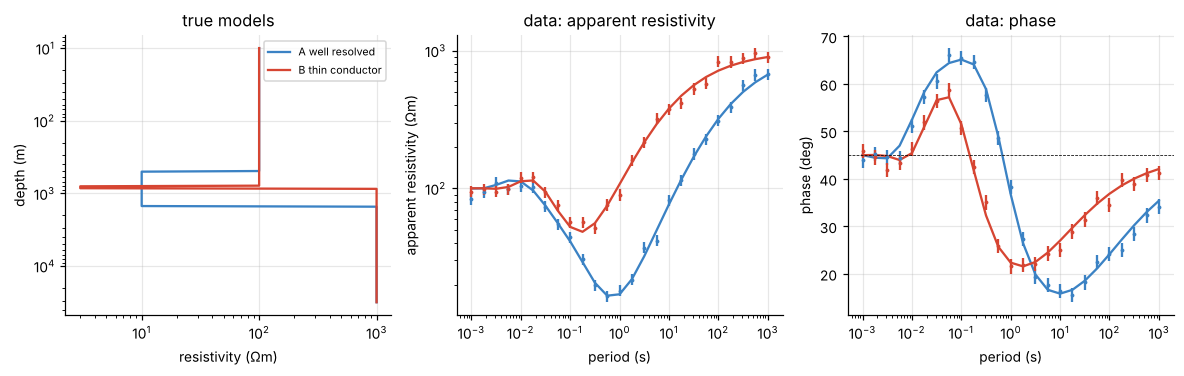

In [4]:
class Problem:
    def __init__(self, name, freqs, nlay, lo, hi, dobs, sig, truth=None, names=None):
        self.name, self.f, self.nlay = name, freqs, nlay
        self.lo, self.hi, self.dobs, self.sig, self.truth = np.asarray(lo, float), np.asarray(hi, float), dobs, sig, truth
        self.d = 2 * nlay - 1
        self.names = names or [f"log ρ{j + 1}" for j in range(nlay)] + [f"log h{j + 1}" for j in range(nlay - 1)]
    def g(self, X):
        return mt1d(X, self.f, self.nlay)
    def inside(self, X):
        return np.all((X >= self.lo) & (X <= self.hi), axis=1)
    def logp(self, X):
        X = np.atleast_2d(X); ok = self.inside(X); out = np.full(len(X), -np.inf)
        if ok.any():
            out[ok] = -0.5 * np.sum(((self.g(X[ok]) - self.dobs) / self.sig) ** 2, axis=1)
        return out

SIG_SYN = np.r_[np.full(25, 0.04), np.full(25, 1.5)]
LO_SYN, HI_SYN = [0, 0, 0, 1.5, 1.5], [4, 4, 4, 3.5, 3.5]
truth_A = np.array([2.0, 1.0, 3.0, np.log10(500), np.log10(1000)])
truth_B = np.array([2.0, np.log10(3), 3.0, np.log10(800), np.log10(60)])
caseA = Problem("A well resolved", F_SYN, 3, LO_SYN, HI_SYN,
                mt1d(truth_A, F_SYN, 3)[0] + SIG_SYN * np.random.default_rng(11).standard_normal(50), SIG_SYN, truth_A)
caseB = Problem("B thin conductor", F_SYN, 3, LO_SYN, HI_SYN,
                mt1d(truth_B, F_SYN, 3)[0] + SIG_SYN * np.random.default_rng(12).standard_normal(50), SIG_SYN, truth_B)

def depth_profile(theta, nlay, z):
    """Resistivity at depths z (m) for each model in theta."""
    theta = np.atleast_2d(theta)
    tops = np.cumsum(10 ** theta[:, nlay:], axis=1)
    idx = (z[None, :, None] >= tops[:, None, :]).sum(-1)
    return np.take_along_axis(10 ** theta[:, :nlay], idx, axis=1)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.3))
zz = np.logspace(1, 4.5, 400)
for case, c in [(caseA, "#3b82c4"), (caseB, "#d64532")]:
    axes[0].plot(depth_profile(case.truth, 3, zz)[0], zz, color=c, label=case.name)
    g_ = case.g(case.truth)[0]
    axes[1].loglog(1 / F_SYN, 10 ** g_[:25], color=c); axes[1].errorbar(1 / F_SYN, 10 ** case.dobs[:25], yerr=10 ** case.dobs[:25] * np.log(10) * 0.04, fmt=".", color=c, ms=3)
    axes[2].semilogx(1 / F_SYN, g_[25:], color=c); axes[2].errorbar(1 / F_SYN, case.dobs[25:], yerr=1.5, fmt=".", color=c, ms=3)
axes[0].set_xscale("log"); axes[0].set_yscale("log"); axes[0].invert_yaxis(); axes[0].set_xlabel("resistivity (Ωm)"); axes[0].set_ylabel("depth (m)"); axes[0].legend(fontsize=7); axes[0].set_title("true models")
axes[1].set_xlabel("period (s)"); axes[1].set_ylabel("apparent resistivity (Ωm)"); axes[1].set_title("data: apparent resistivity")
axes[2].set_xlabel("period (s)"); axes[2].set_ylabel("phase (deg)"); axes[2].set_title("data: phase"); axes[2].axhline(45, color="k", lw=0.5, ls="--")
savefig(fig, "01_cases_and_data"); plt.show()

## 3. Why this is hard

### 3a. The forward model is the bottleneck (in real life)

A 1D model takes microseconds here. A 3D MT forward solve on a realistic mesh takes minutes to
hours. The reference MCMC below uses about half a million forward runs. At one minute per run
that is close to a year. So the honest cost metric is the **number of forward calls**, and a
useful method has to get close to the reference with hundreds of calls, not hundreds of
thousands.

### 3b. Local modes trap samplers

The ensemble sampler used throughout (Section 5.4) starts its walkers spread over the prior.
Some can get stuck in a poor local mode far from the posterior. Below: the log-posterior of
every walker for case A with a plain ensemble sampler.

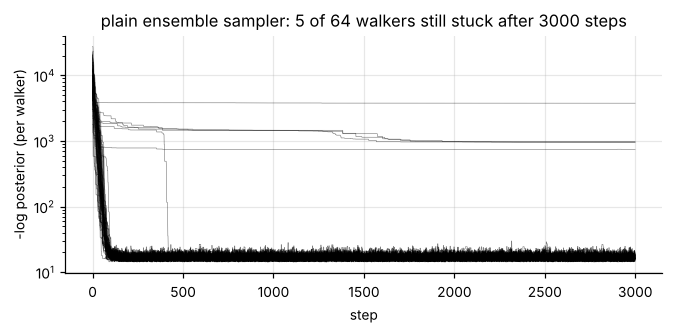

In [5]:
def stretch_move(logp, x0, nsteps, rng, a=2.0, lp0=None):
    """Goodman-Weare affine-invariant ensemble sampler (stretch move), two half-ensembles."""
    W, d = x0.shape
    x = x0.copy(); lp = logp(x) if lp0 is None else lp0.copy()
    half = W // 2; chain, lps, acc = [], [], 0
    for _ in range(nsteps):
        for s in (0, 1):
            idx = np.arange(s * half, (s + 1) * half); oth = np.arange((1 - s) * half, (2 - s) * half)
            z = ((a - 1) * rng.random(half) + 1) ** 2 / a
            partner = x[rng.choice(oth, half)]
            y = partner + z[:, None] * (x[idx] - partner)
            lpy = logp(y)
            ok = np.log(rng.random(half)) < (d - 1) * np.log(z) + lpy - lp[idx]
            x[idx[ok]], lp[idx[ok]] = y[ok], lpy[ok]; acc += ok.sum()
        chain.append(x.copy()); lps.append(lp.copy())
    return np.array(chain), np.array(lps), acc / (nsteps * W)

def lhs(n, lo, hi, rng):
    """Latin hypercube sample of n points in the box [lo, hi]."""
    d = len(lo)
    u = (rng.permuted(np.tile(np.arange(n), (d, 1)), axis=1).T + rng.random((n, d))) / n
    return lo + u * (hi - lo)

_, lps_plain, _ = stretch_move(caseA.logp, lhs(64, caseA.lo, caseA.hi, np.random.default_rng(0)), 3000, np.random.default_rng(0))
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.plot(-lps_plain, color="k", lw=0.4, alpha=0.5); ax.set_yscale("log")
ax.set_xlabel("step"); ax.set_ylabel("-log posterior (per walker)")
stuck = int((lps_plain[-1] < lps_plain[-1].max() - 20).sum())
ax.set_title(f"plain ensemble sampler: {stuck} of 64 walkers still stuck after 3000 steps")
savefig(fig, "02_local_modes"); plt.show()

Stuck walkers do not move and bias every statistic. Two fixes are used (Section 5.4): start
the walkers near the best mode found by a global scan and local optimisation, and during
burn-in move walkers more than 20 log-units below the best onto randomly chosen good walkers.
After burn-in the sampler runs untouched, so the production chain is a valid MCMC. Getting
this right matters even more for surrogates: in development, a sampler started at random
sometimes put *all* walkers in a wrong mode of the surrogate posterior, and active learning
then spent its runs refining the wrong region.

### 3c. The posterior is tiny compared with the prior

Below, the reference posterior of case A (computed in Section 7) is shown inside the prior box.
A surrogate trained on points spread evenly over the box puts almost none of them where the
posterior is. This is the main reason a fixed design fails (Section 7).

### 3d. Equivalence: only combinations are resolved

A thin conductor is seen by MT almost only through its **conductance** $S = h_2/\rho_2$.
Making the layer twice as thick and twice as resistive gives nearly the same data, so the
posterior is a long thin ridge along $\log h_2 - \log\rho_2 = \text{const}$. A Gaussian
(Laplace) approximation describes such a ridge only roughly, and a surrogate must be accurate
along all of it.

Both figures are drawn in Section 7 once the reference posteriors exist.

## 4. Field data: 15 stations near Paralana

Each EDI file holds the full $2\times2$ impedance tensor $Z$ at 43 frequencies (0.0046 to 78 Hz)
with variances. A 1D Earth gives $Z_{xx} = Z_{yy} = 0$ and $Z_{xy} = -Z_{yx}$. Two checks:

* **Swift skew** $\kappa = |Z_{xx} + Z_{yy}| / |Z_{xy} - Z_{yx}|$, near 0 for 1D or 2D Earth.
* **Mode split**: $|\log_{10}(\rho_{a,xy} / \rho_{a,yx})|$, near 0 for 1D.

For inversion the rotation-invariant **determinant** impedance $Z_{\det} = \sqrt{Z_{xx}Z_{yy} - Z_{xy}Z_{yx}}$
is used. EDI impedances are in field units (mV/km/nT), so $\rho_a = 0.2\,|Z|^2 / f$ Ωm.

In [6]:
def read_edi(path):
    txt = open(path).read()
    blocks = {}
    for m in re.finditer(r">(\w[\w.]*)[^\n]*\n([^>]*)", txt):
        key = m.group(1).upper()
        if key in ("FREQ", "ZXXR", "ZXXI", "ZXYR", "ZXYI", "ZYXR", "ZYXI", "ZYYR", "ZYYI", "ZXY.VAR", "ZYX.VAR"):
            blocks[key] = np.array(re.findall(r"[-+]?\d*\.?\d+(?:[eE][-+]?\d+)?", m.group(2)), float)
    f = blocks["FREQ"]
    Z = np.zeros((len(f), 2, 2), complex)
    for i, a in enumerate("XY"):
        for j, b in enumerate("XY"):
            Z[:, i, j] = blocks[f"Z{a}{b}R"] + 1j * blocks[f"Z{a}{b}I"]
    order = np.argsort(f)
    return f[order], Z[order], {k: blocks[k][order] for k in ("ZXY.VAR", "ZYX.VAR")}

rows, sta = [], {}
for fn in EDI_SHA:
    f, Z, var = read_edi(os.path.join(DATA, fn))
    sta[fn[:-4]] = (f, Z, var)
    rxy, ryx = 0.2 / f * np.abs(Z[:, 0, 1]) ** 2, 0.2 / f * np.abs(Z[:, 1, 0]) ** 2
    skew = np.abs(Z[:, 0, 0] + Z[:, 1, 1]) / np.abs(Z[:, 0, 1] - Z[:, 1, 0])
    rows.append(dict(station=fn[:-4], median_skew=np.median(skew), median_mode_split=np.median(np.abs(np.log10(rxy / ryx)))))
st_table = pd.DataFrame(rows).set_index("station").round(3)
st_table["score"] = (st_table.median_skew / st_table.median_skew.median() + st_table.median_mode_split / st_table.median_mode_split.median()).round(2)
st_table.sort_values("score")

,median_skew,median_mode_split,score
station,,,
pb32c,0.070,0.055,1.49
pb30c,0.089,0.041,1.63
pb37c,0.060,0.087,1.63
pb29c,0.046,0.113,1.66
pb44c,0.051,0.106,1.67
pb35c,0.058,0.103,1.74
pb33c,0.055,0.119,1.84
pb23c,0.069,0.135,2.18
pb39c,0.085,0.115,2.23


pb30c: 43 frequencies, reported |Z| error median 0.041; floor 5% applied
1D band: periods up to 1.28 s (21 frequencies; mode split < 0.1 and phase difference < 5 deg)


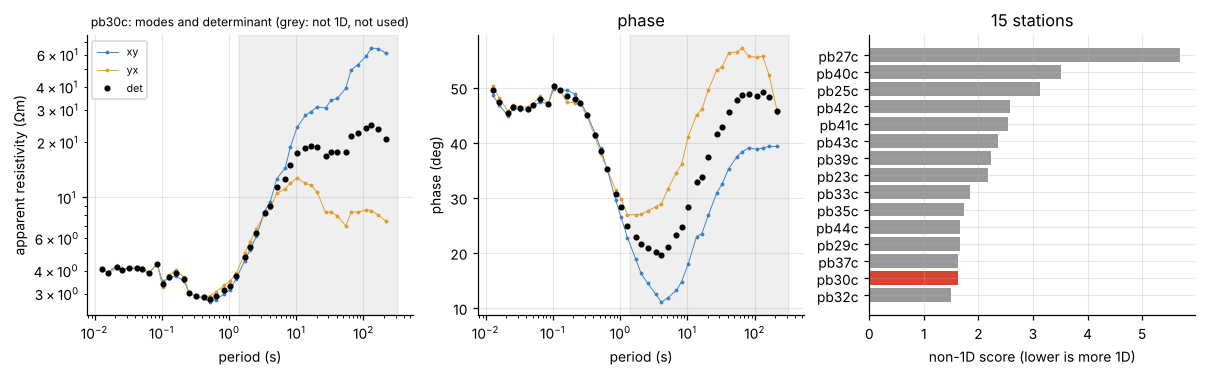

In [7]:
f_fld, Z_fld, var_fld = sta["pb30c"]
zdet = np.sqrt(Z_fld[:, 0, 0] * Z_fld[:, 1, 1] - Z_fld[:, 0, 1] * Z_fld[:, 1, 0])
rel_rep = np.sqrt(0.5 * (var_fld["ZXY.VAR"] + var_fld["ZYX.VAR"])) / np.abs(zdet)
rel = np.maximum(rel_rep, 0.05)                    # 5% error floor on |Z|

# 1D band: from the shortest period up to the first period where the two modes disagree
split = np.abs(np.log10(np.abs(Z_fld[:, 0, 1]) ** 2 / np.abs(Z_fld[:, 1, 0]) ** 2))
dphi = np.abs(np.degrees(np.angle(Z_fld[:, 0, 1])) - np.degrees(np.angle(-Z_fld[:, 1, 0])))
by_period = np.argsort(1 / f_fld)
bad = (split[by_period] > 0.1) | (dphi[by_period] > 5)
n_keep = int(np.argmax(bad)) if bad.any() else len(f_fld)
keep = np.sort(by_period[:n_keep])
T_max = (1 / f_fld[keep]).max()
d_fld = np.r_[np.log10(0.2 / f_fld[keep] * np.abs(zdet[keep]) ** 2), np.degrees(np.angle(zdet[keep]))]
s_fld = np.r_[2 * rel[keep] / np.log(10), np.degrees(rel[keep])]
print(f"pb30c: {len(f_fld)} frequencies, reported |Z| error median {np.median(rel_rep):.3f}; floor 5% applied")
print(f"1D band: periods up to {T_max:.2f} s ({len(keep)} frequencies; mode split < 0.1 and phase difference < 5 deg)")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.3))
F_ = len(f_fld)
for lab, zc, c in [("xy", Z_fld[:, 0, 1], "#3b82c4"), ("yx", -Z_fld[:, 1, 0], "#e39b2d"), ("det", zdet, "k")]:
    axes[0].loglog(1 / f_fld, 0.2 / f_fld * np.abs(zc) ** 2, ".-" if lab != "det" else "o", ms=3, color=c, label=lab, lw=0.6)
    axes[1].semilogx(1 / f_fld, np.degrees(np.angle(zc)) % 180 if lab == "yx" else np.degrees(np.angle(zc)), ".-" if lab != "det" else "o", ms=3, color=c, lw=0.6)
for ax_ in axes[:2]:
    ax_.axvspan(T_max * 1.1, (1 / f_fld).max() * 1.5, color="#999999", alpha=0.15)
axes[0].set_xlabel("period (s)"); axes[0].set_ylabel("apparent resistivity (Ωm)"); axes[0].legend(fontsize=7); axes[0].set_title("pb30c: modes and determinant (grey: not 1D, not used)", fontsize=8)
axes[1].set_xlabel("period (s)"); axes[1].set_ylabel("phase (deg)"); axes[1].set_title("phase")
ss = st_table.sort_values("score")
axes[2].barh(ss.index, ss.score, color=["#d64532" if s_ == "pb30c" else "#999999" for s_ in ss.index])
axes[2].set_xlabel("non-1D score (lower is more 1D)"); axes[2].set_title("15 stations")
savefig(fig, "03_field_eda"); plt.show()

**What the field data show.** pb30c is among the most 1D stations by median skew and mode
split, but the medians hide a period dependence: the two modes agree closely up to about
1 s and then separate (by 8 s the apparent resistivities differ by a factor of 1.6, and the
phases by 20°). Long periods see 2D or 3D structure, so a 1D inversion of the whole band would
fit effects the model cannot represent. Only the **1D band** is used: from the shortest period
up to the first period where the mode split exceeds 0.1 decades or the phases differ by more
than 5°. In that band apparent resistivity falls from about 4 Ωm to about 3 Ωm and the phase
swings from 45° to 50° and down toward 30°: a conductive cover over a more conductive layer
over more resistive rock, within the top one to two kilometres. Reported errors are around 4%;
a 5% floor on $|Z|$ is applied, as is common practice.

**How many layers?** Two field models are used. **F2** (2 layers) already fits the 1D band
within the noise (checked in 7.1), so it is the model the data support. **F3** (3 layers) is
over-parameterised on purpose: its posterior spreads over a large part of the prior box, the
opposite of the synthetic cases, which tests whether active learning still helps when the
posterior is broad.

In [8]:
caseF2 = Problem("Field pb30c, 2 layers", f_fld[keep], 2, [-1, -1, 1], [4, 4, 4], d_fld, s_fld)
caseF3 = Problem("Field pb30c, 3 layers", f_fld[keep], 3, [-1, -1, -1, 1, 1], [4, 4, 4, 4, 4], d_fld, s_fld)
CASES = {"A": caseA, "B": caseB, "F2": caseF2, "F3": caseF3}

## 5. First-principles design

### 5.1 Emulate the data, not the likelihood

Two choices are common: a GP on the scalar log-likelihood, or a GP on the forward model's
output. The log-likelihood spans many orders of magnitude over the prior and changes with
every new data set. The **data vector** is smooth in $\theta$ and does not depend on the
observations, so it is the better target here.

The output has $2F$ = 50 to 86 numbers. They are strongly correlated across frequency, so they
are compressed with PCA. Outputs are standardised, $\tilde g = (g - \bar g)/s$, and
$\tilde g \approx \sum_{k=1}^{q} c_k(\theta)\, v_k$ with $q \le 12$ principal directions
$v_k$. Each coefficient $c_k(\theta)$ gets its own GP.

### 5.2 The GP

Each GP has a Matérn-5/2 kernel with one length scale per parameter (ARD) and a small nugget:

$$
k(\theta, \theta') = s^2 \left(1 + \sqrt5 r + \tfrac53 r^2\right) e^{-\sqrt5 r}, \qquad
r^2 = \sum_{m} \frac{(\theta_m - \theta'_m)^2}{\ell_m^2}.
$$

Matérn-5/2 assumes twice-differentiable functions, less smooth than the squared-exponential
kernel, which is usually safer for physical models. Hyperparameters are fitted by maximum
marginal likelihood (scikit-learn).

### 5.3 A surrogate likelihood that knows its own error

The GP gives a mean $m(\theta)$ and a variance $v(\theta)$ for every output (diagonal, through
the PCA directions, plus the variance of the dropped components). Treating the emulator error
as extra Gaussian noise gives

$$
\log \tilde p(\theta \mid d) = -\frac12 \sum_i \left[\frac{(m_i(\theta) - d_i)^2}{\sigma_i^2 + v_i(\theta)} + \log\big(\sigma_i^2 + v_i(\theta)\big)\right].
$$

Where the GP is unsure, the surrogate posterior widens instead of becoming falsely confident.

### 5.4 Sampler

The affine-invariant ensemble sampler (stretch move): 64 walkers, each moved along the line to
a random walker of the other half-ensemble, $y = x_p + z(x - x_p)$ with
$p(z) \propto 1/\sqrt z$ on $[1/2, 2]$, accepted with probability
$\min\{1, z^{d-1} p(y)/p(x)\}$. It needs no tuning and handles strongly correlated posteriors
(like the equivalence ridge) well, because its moves follow the shape of the ensemble.

**Starting point.** The posterior has local modes (3b). If every walker starts in, or falls into,
the same wrong mode, no reset rule can help. So each run first scans the prior with 3000 Latin
hypercube points, runs Nelder-Mead from the 6 best, and starts the walkers in a small ball
around the best optimum. For a surrogate, the training runs with the best **true** misfit
are added as starting points: their outputs are already known, so this costs no forward
calls, and it stops the sampler from settling in a spurious mode at the edge of the box
while the real one is sitting next to the best training runs. Stragglers are still reset
during burn-in. For the reference the scan adds a few thousand true calls to a run of about
half a million.

### 5.5 Active learning: put forward runs where the posterior is

Start from 20 Latin hypercube points. Then repeat, 10 points per round:

1. fit the emulator, run a short MCMC on the surrogate posterior;
2. score each surrogate-posterior sample by how unsure the emulator is *in units of the data
   errors*, $a(\theta) = \sum_i v_i(\theta)/\sigma_i^2$;
3. pick the 10 highest scores greedily, damping the score of candidates near already picked
   points (a soft repulsion in the normalised box), so the batch is spread out;
4. run the true model at those 10 points and refit.

The criterion asks "where is the posterior, and where am I unsure there?". Uncertainty
outside the posterior is ignored, because it does not change the answer.

**When to stop.** In development, a fixed budget proved unreliable: the same number of runs
gave a reference-quality posterior for one random start and a wrong one for another. So the
loop stops on evidence instead: when two successive rounds change the surrogate posterior by
less than 0.25 (in the W1/sd metric of Section 6.1) **and** the best training run fits the
data at noise level ($\chi^2/N < 2$), or at 200 runs. Both checks use only quantities already
in hand, so the rule costs no forward calls. The threshold sits just above the Monte Carlo
noise of the short round chains (about 0.15 to 0.25 on the equivalence ridge of case B); a
tighter value made the rule wait for noise to vanish.

### 5.6 Delayed acceptance: an exact variant

A surrogate posterior is an approximation. Delayed acceptance makes it exact: a proposal must
first pass the surrogate test, and only then is the true model run for a correction test,

$$
\alpha_1 = \min\Big\{1, z^{d-1}\frac{\tilde p(y)}{\tilde p(x)}\Big\}, \qquad
\alpha_2 = \min\Big\{1, \frac{p(y)\,\tilde p(x)}{p(x)\,\tilde p(y)}\Big\}.
$$

The chain targets the true posterior, and true-model calls are spent only on proposals the
surrogate already likes.

In [9]:
class PCAGP:
    def __init__(self, max_comp=12, var_keep=0.99999, restarts=1):
        self.max_comp, self.var_keep, self.restarts = max_comp, var_keep, restarts
    def fit(self, X, Y):
        self.mu, self.sd = Y.mean(0), Y.std(0) + 1e-9
        Ys = (Y - self.mu) / self.sd
        _, S, Vt = np.linalg.svd(Ys, full_matrices=False)
        ev = S ** 2 / np.sum(S ** 2)
        q = min(int(np.searchsorted(np.cumsum(ev), self.var_keep) + 1), self.max_comp, len(S))
        self.V, self.explained = Vt[:q], ev
        self.resid_var = np.sum(S[q:] ** 2) / Ys.size
        C = Ys @ self.V.T
        self.gps = []
        for i in range(q):
            k = ConstantKernel(1.0, (1e-3, 1e3)) * Matern(np.ones(X.shape[1]), (1e-2, 1e2), nu=2.5) + WhiteKernel(1e-6, (1e-10, 1e-1))
            self.gps.append(GaussianProcessRegressor(k, normalize_y=True, n_restarts_optimizer=self.restarts, random_state=0).fit(X, C[:, i]))
        return self
    def predict(self, X):
        m = np.zeros((len(X), len(self.gps))); v = np.zeros_like(m)
        for i, gp in enumerate(self.gps):
            mu_, sd_ = gp.predict(X, return_std=True); m[:, i], v[:, i] = mu_, sd_ ** 2
        return self.mu + (m @ self.V) * self.sd, ((v @ self.V ** 2) + self.resid_var) * self.sd ** 2

def surrogate_logp(prob, em):
    def f(X):
        X = np.atleast_2d(X); ok = prob.inside(X); out = np.full(len(X), -np.inf)
        if ok.any():
            m, v = em.predict(X[ok]); s2 = prob.sig ** 2 + v
            out[ok] = -0.5 * np.sum((m - prob.dobs) ** 2 / s2 + np.log(s2), axis=1)
        return out
    return f

def find_mode(logp, lo, hi, rng, n_scan=3000, n_opt=6, maxiter=300, starts=None):
    """Global start: Nelder-Mead from the best points of a Latin hypercube scan of the prior,
    plus any extra starting points supplied (e.g. the training runs with the best true misfit)."""
    X = lhs(n_scan, lo, hi, rng); lp = logp(X)
    cands = X[np.argsort(-lp)[:n_opt]]
    if starts is not None:
        cands = np.vstack([cands, starts])
    best_x, best_f = None, np.inf
    for x0 in cands:
        r = optimize.minimize(lambda t: -logp(np.clip(t, lo, hi)[None])[0], x0, method="Nelder-Mead",
                              options=dict(maxiter=maxiter, xatol=1e-4, fatol=1e-3))
        if r.fun < best_f:
            best_x, best_f = np.clip(r.x, lo, hi), r.fun
    return best_x

def sample(logp, lo, hi, rng, W=64, burn=2000, steps=4000, reset_every=250, x0=None, starts=None):
    """Ensemble MCMC started around the best mode found by find_mode, with straggler reset
    during burn-in only. Returns flat production samples."""
    if x0 is None:
        centre = find_mode(logp, lo, hi, rng, starts=starts)
        x0 = np.clip(centre + 0.01 * (hi - lo) * rng.standard_normal((W, len(lo))), lo, hi)
    x = x0.copy()
    for _ in range(0, burn, reset_every):
        ch, lps, _ = stretch_move(logp, x, reset_every, rng)
        x, lp = ch[-1], lps[-1]
        bad = lp < lp.max() - 20
        if bad.any() and (~bad).sum() >= 2:
            good = np.flatnonzero(~bad)
            x[bad] = np.clip(x[rng.choice(good, bad.sum())] + 1e-3 * (hi - lo) * rng.standard_normal((bad.sum(), len(lo))), lo, hi)
    ch, _, acc = stretch_move(logp, x, steps, rng)
    return ch.reshape(-1, len(lo)), acc

def best_runs(prob, X, Y, k=5):
    """Training runs with the best true log-likelihood, computed from outputs already in hand."""
    ll = -0.5 * np.sum(((Y - prob.dobs) / prob.sig) ** 2, axis=1)
    return X[np.argsort(-ll)[:k]]

def fit_fixed(prob, N, seed):
    X = lhs(N, prob.lo, prob.hi, np.random.default_rng(seed)); Y = prob.g(X)
    return PCAGP().fit(X, Y), X, best_runs(prob, X, Y)

def fit_active(prob, seed, N0=20, batch=10, N_max=200, tol=0.25, chi2_max=2.0, length=0.05, ref=None):
    """Active learning with a stopping rule. Each round: fit the emulator, sample its posterior
    (short run), add `batch` runs where the emulator is least sure in units of data noise.
    Stop when two successive rounds change the surrogate posterior by less than `tol` (W1/sd)
    and the best training run fits the data with chi^2/N < chi2_max, or at N_max runs.
    If `ref` is given, the round posteriors are also scored against it (for plotting only)."""
    rng = np.random.default_rng(seed)
    X = lhs(N0, prob.lo, prob.hi, rng); Y = prob.g(X)
    hist, prev, stable = [], None, 0
    while True:
        em = PCAGP(restarts=0).fit(X, Y)
        s_, _ = sample(surrogate_logp(prob, em), prob.lo, prob.hi, rng, W=32, burn=300, steps=200, starts=best_runs(prob, X, Y))
        chi2 = np.min(np.sum(((Y - prob.dobs) / prob.sig) ** 2, axis=1)) / len(prob.dobs)
        change = w1_score(s_, prev) if prev is not None else np.inf
        stable = stable + 1 if change < tol else 0
        hist.append(dict(N=len(X), change=change, best_chi2=chi2, W1_ref=w1_score(s_, ref) if ref is not None else np.nan))
        prev = s_
        if (stable >= 2 and chi2 < chi2_max) or len(X) >= N_max:
            break
        cand = s_[rng.choice(len(s_), min(1500, len(s_)), replace=False)]
        _, v = em.predict(cand)
        score = np.sum(v / prob.sig ** 2, axis=1)
        pick = []
        for _ in range(min(batch, N_max - len(X))):
            i = int(np.argmax(score)); pick.append(i)
            dist = np.linalg.norm((cand - cand[i]) / (prob.hi - prob.lo), axis=1)
            score = score * (1 - np.exp(-(dist / length) ** 2))
        Xn = cand[pick]; X = np.vstack([X, Xn]); Y = np.vstack([Y, prob.g(Xn)])
    return PCAGP(restarts=1).fit(X, Y), X, best_runs(prob, X, Y), pd.DataFrame(hist)

def delayed_acceptance(prob, em, start, nsteps, rng, W=32, burn=500):
    """start: samples from the surrogate posterior; W of them seed the walkers."""
    lps_ = surrogate_logp(prob, em)
    x = start[rng.choice(len(start), W, replace=False)].copy(); ls, lt = lps_(x), prob.logp(x)
    half, d = W // 2, prob.d; chain, ncall = [], 0
    for t in range(nsteps):
        for s in (0, 1):
            idx = np.arange(s * half, (s + 1) * half); oth = np.arange((1 - s) * half, (2 - s) * half)
            z = (rng.random(half) + 1) ** 2 / 2
            partner = x[rng.choice(oth, half)]; y = partner + z[:, None] * (x[idx] - partner)
            lsy = lps_(y)
            p1 = np.log(rng.random(half)) < (d - 1) * np.log(z) + lsy - ls[idx]
            if p1.any():
                lty = np.full(half, -np.inf); lty[p1] = prob.logp(y[p1]); ncall += int(p1.sum())
                ok = p1 & (np.log(rng.random(half)) < (lty - lt[idx]) - (lsy - ls[idx]))
                x[idx[ok]], ls[idx[ok]], lt[idx[ok]] = y[ok], lsy[ok], lty[ok]
        if t >= burn:
            chain.append(x.copy())
    return np.array(chain).reshape(-1, d), ncall

## 6. Baselines

| | method | forward calls | what it assumes |
|---|---|---|---|
| **reference** | ensemble MCMC with the true model (two independent runs) | about $5\times10^5$ | nothing; this is the answer |
| **Laplace** | Gauss-Newton best fit from 8 random starts, then a Gaussian with covariance $(J^\top \Sigma^{-1} J)^{-1}$ | hundreds | posterior close to Gaussian |
| **GP, fixed design** | kriging surrogate trained on a Latin hypercube over the prior box, then MCMC on it | $N$ | the design covers the posterior |
| **GP, active learning** | Section 5.5, run until the stopping rule fires, 3 seeds | $N$ (chosen by the rule) | the emulator's error estimate is honest |
| **delayed acceptance** | Section 5.6, started from the first active-learning surrogate | $N$ + true calls in stage 2 | none (exact) |

### 6.1 Metric

For each parameter, the Wasserstein-1 distance between the method's marginal posterior and the
reference marginal, divided by the reference standard deviation, then averaged over
parameters:

$$
\mathrm{W}_1/\sigma = \frac{1}{D}\sum_{m=1}^{D} \frac{W_1\big(p_m^{\text{method}}, p_m^{\text{ref}}\big)}{\mathrm{sd}(p_m^{\text{ref}})} .
$$

0 is perfect. Two independent reference runs set the Monte Carlo noise floor. A value of 1
means the marginals are typically one posterior standard deviation apart.

In [10]:
def w1_score(post, ref):
    return float(np.mean([stats.wasserstein_distance(post[:, i], ref[:, i]) / ref[:, i].std() for i in range(ref.shape[1])]))

def laplace(prob, starts=8, seed=0):
    rng = np.random.default_rng(seed); best = None
    for s in range(starts):
        r = optimize.least_squares(lambda t: (prob.g(t)[0] - prob.dobs) / prob.sig, lhs(1, prob.lo, prob.hi, rng)[0],
                                   bounds=(prob.lo, prob.hi), x_scale=prob.hi - prob.lo)
        if best is None or r.cost < best.cost:
            best = r
    C = np.linalg.pinv(best.jac.T @ best.jac)
    return best.x, C, np.random.default_rng(seed).multivariate_normal(best.x, C, 20000)

## 7. Experiments with a known answer

### 7.1 Reference posteriors

In [11]:
REF, REF_NOISE, REF_CALLS = {}, {}, {}
for key in ["A", "B", "F2", "F3"]:
    prob = CASES[key]
    Calls.n = 0; t0 = time.time()
    r1, _ = sample(prob.logp, prob.lo, prob.hi, np.random.default_rng(100), burn=3000, steps=6000)
    REF_CALLS[key] = Calls.n
    r2, _ = sample(prob.logp, prob.lo, prob.hi, np.random.default_rng(200), burn=3000, steps=6000)
    REF[key], REF_NOISE[key] = r1, w1_score(r2, r1)
    print(f"case {key}: {REF_CALLS[key]:,} calls, {time.time() - t0:.0f} s for two runs, "
          f"run-to-run W1/sd = {REF_NOISE[key]:.3f}")
    print("   mean", r1.mean(0).round(3), " sd", r1.std(0).round(3))
best_fit = {k: REF[k][np.argmax(CASES[k].logp(REF[k][-5000:]))] for k in REF}
for k in REF:
    chi2 = -2 * CASES[k].logp(best_fit[k])[0] / len(CASES[k].dobs)
    print(f"case {k}: best chi^2/N = {chi2:.2f}")

case A: 581,693 calls, 11 s for two runs, run-to-run W1/sd = 0.006
   mean [1.973 0.978 3.027 2.722 2.979]  sd [0.013 0.036 0.022 0.016 0.038]


case B: 536,868 calls, 10 s for two runs, run-to-run W1/sd = 0.015
   mean [2.008 0.883 3.022 2.881 2.218]  sd [0.013 0.353 0.015 0.038 0.368]


case F2: 530,011 calls, 8 s for two runs, run-to-run W1/sd = 0.014
   mean [0.58  3.223 2.934]  sd [0.01  0.478 0.016]


case F3: 462,041 calls, 10 s for two runs, run-to-run W1/sd = 0.025
   mean [1.177 0.462 2.804 1.585 2.755]  sd [0.851 0.241 0.569 0.561 0.34 ]
case A: best chi^2/N = 0.65
case B: best chi^2/N = 0.75
case F2: best chi^2/N = 0.65
case F3: best chi^2/N = 0.43


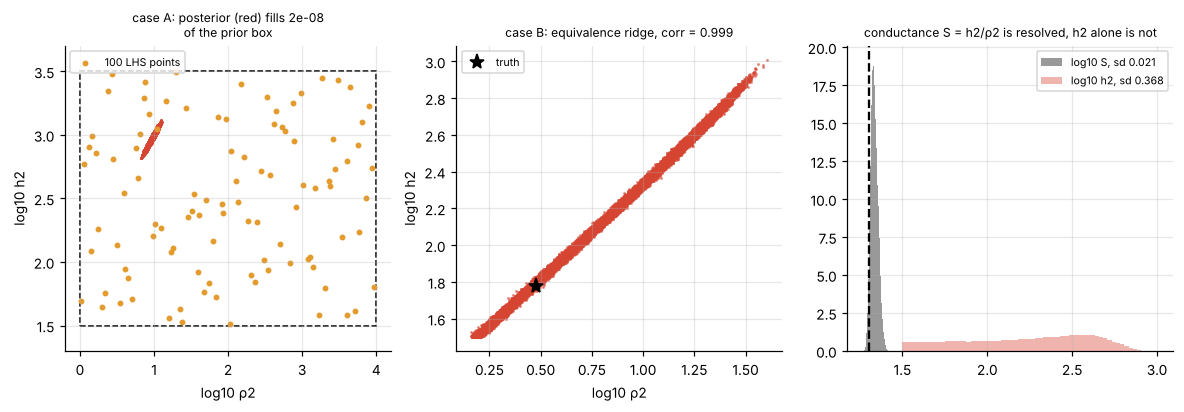

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
ax = axes[0]
ax.add_patch(plt.Rectangle((0, 1.5), 4, 2, fill=False, ls="--", color="k"))
ax.scatter(REF["A"][::20, 1], REF["A"][::20, 4], s=1, color=COL["active"])
ax.scatter(*lhs(100, caseA.lo, caseA.hi, np.random.default_rng(1))[:, [1, 4]].T, s=8, color=COL["lhs"], label="100 LHS points")
ax.set_xlim(-0.2, 4.2); ax.set_ylim(1.3, 3.7); ax.set_xlabel("log10 ρ2"); ax.set_ylabel("log10 h2"); ax.legend(fontsize=7, loc="upper left")
box_vol = np.prod(caseA.hi - caseA.lo); post_vol = np.prod(4 * REF["A"].std(0))
ax.set_title(f"case A: posterior (red) fills {post_vol / box_vol:.0e}\nof the prior box", fontsize=8)
ax = axes[1]
ax.scatter(REF["B"][::10, 1], REF["B"][::10, 4], s=1, color=COL["active"], alpha=0.5)
ax.plot(truth_B[1], truth_B[4], "k*", ms=10, label="truth")
ax.set_xlabel("log10 ρ2"); ax.set_ylabel("log10 h2"); ax.legend(fontsize=7)
ax.set_title(f"case B: equivalence ridge, corr = {np.corrcoef(REF['B'][:, 1], REF['B'][:, 4])[0, 1]:.3f}", fontsize=8)
ax = axes[2]
S_ = REF["B"][:, 4] - REF["B"][:, 1]
ax.hist(S_, 60, color="#999999", density=True, label=f"log10 S, sd {S_.std():.3f}")
ax.hist(REF["B"][:, 4], 60, color=COL["active"], alpha=0.4, density=True, label=f"log10 h2, sd {REF['B'][:, 4].std():.3f}")
ax.axvline(truth_B[4] - truth_B[1], color="k", ls="--"); ax.legend(fontsize=7); ax.set_title("conductance S = h2/ρ2 is resolved, h2 alone is not", fontsize=8)
savefig(fig, "04_posterior_geometry"); plt.show()

Case A's posterior occupies a tiny fraction of the prior box, and case B is a ridge with a
correlation near 1 between $\log\rho_2$ and $\log h_2$. The conductance is known to about 0.02
decades, while the thickness alone is uncertain by about 0.35 decades.

### 7.2 Accuracy against forward calls

For each case: the fixed design with $N \in \{50, 100, 200, 400\}$; active learning from three
seeds, each run until its stopping rule fires (Section 5.5); Laplace; and delayed acceptance
started from the first active-learning surrogate. Every final surrogate posterior is sampled
with the same MCMC settings (64 walkers, 1500 burn-in steps, 3000 production steps).

Thin red lines show, for each seed, the short surrogate posterior of every active-learning
round scored against the reference. These scores are for the plot only; the stopping rule
never sees the reference.

In [13]:
def run_case(key, fixed_N=(50, 100, 200, 400), seeds=(0, 1, 2)):
    prob, ref = CASES[key], REF[key]
    rows, store, hists = [], {}, []
    Calls.n = 0
    x_map, C, lap = laplace(prob)
    rows.append(dict(case=key, method="laplace", seed=0, calls=Calls.n, W1=w1_score(lap, ref))); store["laplace"] = lap
    for N in fixed_N:
        em, X, st_ = fit_fixed(prob, N, 1000 + N)
        p, _ = sample(surrogate_logp(prob, em), prob.lo, prob.hi, np.random.default_rng(1), burn=1500, steps=3000, starts=st_)
        rows.append(dict(case=key, method="lhs", seed=0, calls=N, W1=w1_score(p, ref))); store[f"lhs{N}"] = (p, X, em)
    for sd in seeds:
        t0 = time.time()
        em, X, st_, h = fit_active(prob, seed=sd, ref=ref)
        p, _ = sample(surrogate_logp(prob, em), prob.lo, prob.hi, np.random.default_rng(1), burn=1500, steps=3000, starts=st_)
        rows.append(dict(case=key, method="active", seed=sd, calls=len(X), W1=w1_score(p, ref), seconds=time.time() - t0))
        hists.append(h.assign(case=key, seed=sd))
        if sd == seeds[0]:
            store["active"] = (p, X, em)
    p0, _, em0 = store["active"]
    Calls.n = 0
    pda, _ = delayed_acceptance(prob, em0, p0, 3000, np.random.default_rng(3))
    rows.append(dict(case=key, method="da", seed=0, calls=len(store["active"][1]) + Calls.n, W1=w1_score(pda, ref))); store["da"] = pda
    rows.append(dict(case=key, method="reference", seed=0, calls=REF_CALLS[key], W1=REF_NOISE[key]))
    return pd.DataFrame(rows), store, pd.concat(hists)

t0 = time.time()
resA, stA, hA = run_case("A")
print(f"case A done in {time.time() - t0:.0f} s"); t0 = time.time()
resB, stB, hB = run_case("B")
print(f"case B done in {time.time() - t0:.0f} s")
res_syn = pd.concat([resA, resB]); res_syn.to_csv(f"{RES}/synthetic_cost_accuracy.csv", index=False)
hist_syn = pd.concat([hA, hB]); hist_syn.to_csv(f"{RES}/active_learning_rounds_synthetic.csv", index=False)
res_syn.round(3)

case A done in 673 s


case B done in 725 s


,case,method,seed,calls,W1,seconds
0,A,laplace,0,506,0.057,NaN
1,A,lhs,0,50,15.782,NaN
2,A,lhs,0,100,4.456,NaN
3,A,lhs,0,200,7.637,NaN
4,A,lhs,0,400,1.012,NaN
5,A,active,0,70,0.034,108.001
6,A,active,1,90,0.032,141.743
7,A,active,2,70,0.033,107.349
8,A,da,0,53007,0.025,NaN
9,A,reference,0,581693,0.006,NaN


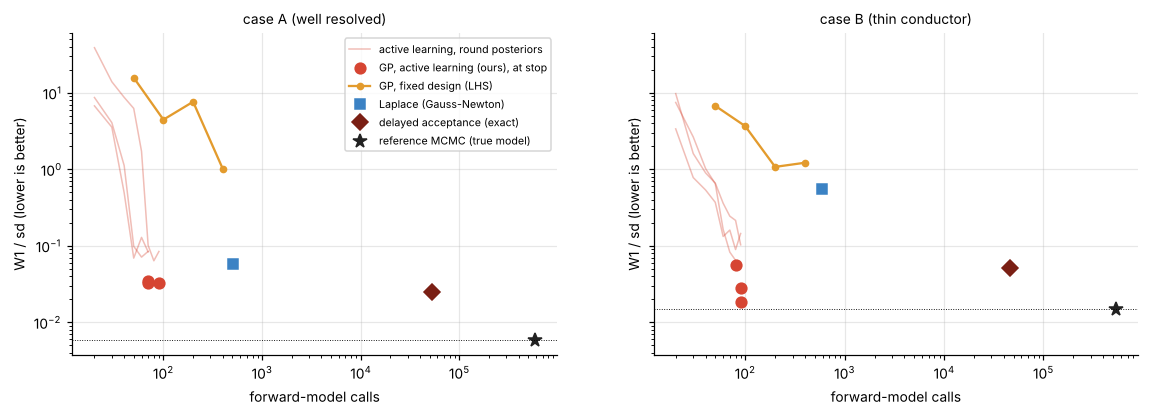

In [14]:
def cost_plot(ax, res, hist, title):
    for sd, h in hist.groupby("seed"):
        ax.plot(h.N, h.W1_ref, "-", color=COL["active"], alpha=0.35, lw=1, label="active learning, round posteriors" if sd == 0 else None)
    q = res[res.method == "active"]
    ax.plot(q.calls, q.W1, "o", ms=7, color=COL["active"], label=LAB["active"] + ", at stop")
    q = res[res.method == "lhs"].sort_values("calls")
    ax.plot(q.calls, q.W1, "o-", ms=4, color=COL["lhs"], label=LAB["lhs"])
    for m, mk in [("laplace", "s"), ("da", "D"), ("reference", "*")]:
        q = res[res.method == m]
        ax.plot(q.calls, q.W1, mk, ms=9 if m == "reference" else 7, color=COL.get(m, "k"), label=LAB[m])
    ax.axhline(res[res.method == "reference"].W1.iloc[0], color="k", lw=0.6, ls=":")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("forward-model calls"); ax.set_ylabel("W1 / sd (lower is better)")
    ax.set_title(title, fontsize=9)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8), sharey=True)
cost_plot(axes[0], resA, hA, "case A (well resolved)"); cost_plot(axes[1], resB, hB, "case B (thin conductor)")
axes[0].legend(fontsize=7, loc="upper right")
savefig(fig, "05_cost_accuracy_synthetic"); plt.show()

**Reading the cost-accuracy plot.**

* **Active learning reaches reference quality with 70 to 90 forward calls**, for all three
  seeds in both cases (W1/sd 0.03 in case A, 0.02 to 0.06 in case B). The reference used
  about 550,000 calls, so that is roughly 6,000 times fewer.
* **The stopping rule works**: every seed stopped on its own, at the point where its round
  posteriors (thin lines) had levelled off near the reference, without ever seeing the
  reference.
* **The fixed design fails** even with 400 runs (W1/sd 1.0 to 1.2 at best): its points land
  almost nowhere near a posterior that fills a $10^{-8}$ fraction of the box.
* **Laplace** is good in case A (0.06 with about 500 calls), where the posterior is close to
  Gaussian, and poor in case B (0.55), where it cannot follow the equivalence ridge or the
  prior bound.
* **Delayed acceptance** is exact and matches the reference, but needs about 50,000 true calls:
  ten times fewer than plain MCMC, still about 600 times more than the surrogate alone. It
  buys a guarantee, not a large saving.

### 7.3 Where do the training runs go?

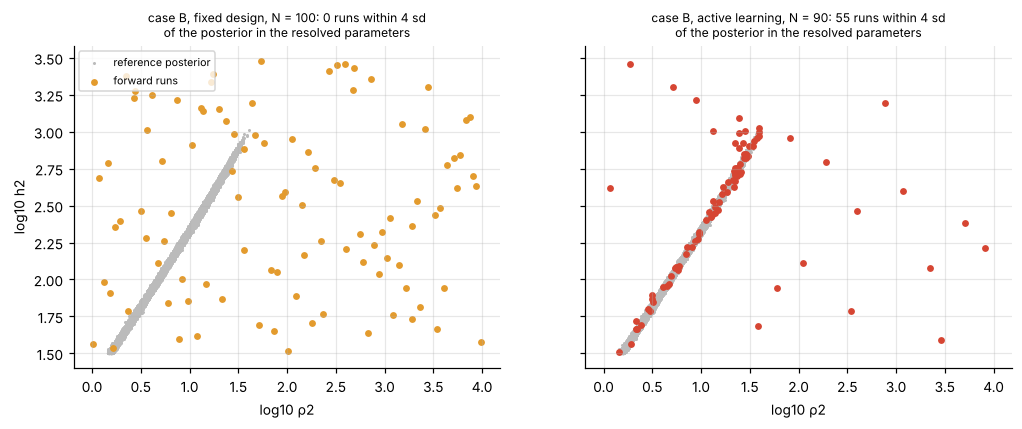

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True, sharey=True)
for ax, (lab, key) in zip(axes, [("fixed design, N = 100", "lhs100"), (f"active learning, N = {len(stB['active'][1])}", "active")]):
    X = stB[key][1]
    ax.scatter(REF["B"][::10, 1], REF["B"][::10, 4], s=1, color="#bbbbbb", label="reference posterior")
    ax.scatter(X[:, 1], X[:, 4], s=12, color=COL["lhs" if "lhs" in key else "active"], label="forward runs")
    n_in = int(np.sum(np.abs(((X - REF["B"].mean(0)) / REF["B"].std(0))[:, [0, 2, 3]]).max(1) < 4))
    ax.set_title(f"case B, {lab}: {n_in} runs within 4 sd\nof the posterior in the resolved parameters", fontsize=8)
    ax.set_xlabel("log10 ρ2")
axes[0].set_ylabel("log10 h2"); axes[0].legend(fontsize=7, loc="upper left")
savefig(fig, "06_training_points"); plt.show()

The fixed design puts none of its 100 runs near the posterior in the well-resolved parameters.
Active learning puts most of its runs along the ridge, plus a few exploratory ones elsewhere.

### 7.4 Does the emulator know when it is wrong?

At 1000 reference-posterior samples (true-model runs used for checking only, not counted),
compare the emulator's error with its own predicted standard deviation,
$z = (m - g)/\sqrt{v}$. If the uncertainty is honest, $z$ is roughly standard normal and about
90% of $|z|$ fall below 1.645. Also shown: the error in units of the data noise,
$(m - g)/\sigma$, which is what the likelihood actually sees.

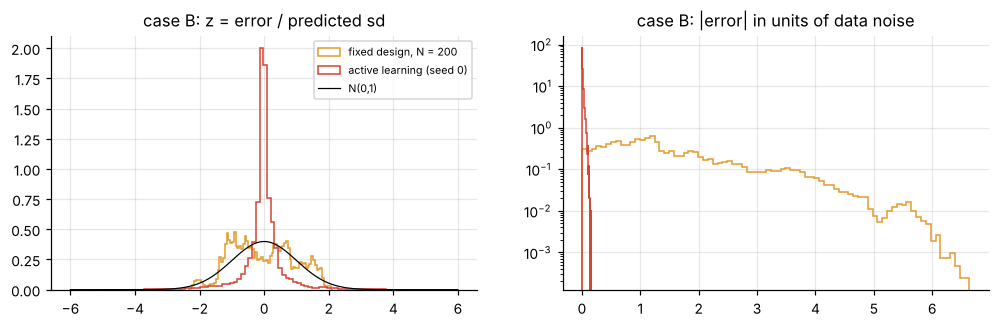

,case,emulator,coverage_90,rms_error_in_noise_units
0,A,"fixed design, N = 200",0.847,2.352
1,B,"fixed design, N = 200",0.930,1.916
2,A,active learning (seed 0),0.999,0.014
3,B,active learning (seed 0),0.961,0.022


In [16]:
def calib(prob, em, ref, n=1000, seed=0):
    pts = ref[np.random.default_rng(seed).choice(len(ref), n, replace=False)]
    m, v = em.predict(pts); g_ = mt1d(pts, prob.f, prob.nlay)
    z = (m - g_) / np.sqrt(v); e = (m - g_) / prob.sig
    return z.ravel(), e.ravel()

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
rows = []
for key, lab, c in [("lhs200", "fixed design, N = 200", COL["lhs"]), ("active", "active learning (seed 0)", COL["active"])]:
    for case_key, st in [("A", stA), ("B", stB)]:
        z, e = calib(CASES[case_key], st[key][2], REF[case_key])
        rows.append(dict(case=case_key, emulator=lab, coverage_90=np.mean(np.abs(z) < 1.645), rms_error_in_noise_units=np.sqrt(np.mean(e ** 2))))
        if case_key == "B":
            axes[0].hist(np.clip(z, -6, 6), 80, density=True, histtype="step", color=c, label=lab)
            axes[1].hist(np.clip(np.abs(e), 0, 20), 80, density=True, histtype="step", color=c, label=lab)
xg = np.linspace(-6, 6, 200); axes[0].plot(xg, stats.norm.pdf(xg), "k", lw=0.8, label="N(0,1)")
axes[0].set_title("case B: z = error / predicted sd"); axes[0].legend(fontsize=7)
axes[1].set_title("case B: |error| in units of data noise"); axes[1].set_yscale("log")
calib_table = pd.DataFrame(rows).round(3); calib_table.to_csv(f"{RES}/emulator_calibration.csv", index=False)
savefig(fig, "07_emulator_calibration"); plt.show()
calib_table

**Reading the calibration.** The active-learning emulator is accurate where it matters: its
error at posterior samples is about 0.01 to 0.02 of the data noise, and its predicted
uncertainty is, if anything, conservative ($z$ narrower than standard normal, 90% intervals
covering 96 to 100%). The fixed-design emulator's uncertainty is roughly honest (85 to 93%
coverage), but its errors are about twice the data noise, so the surrogate posterior is wide
and in the wrong place.

### 7.5 Posterior marginals, case B

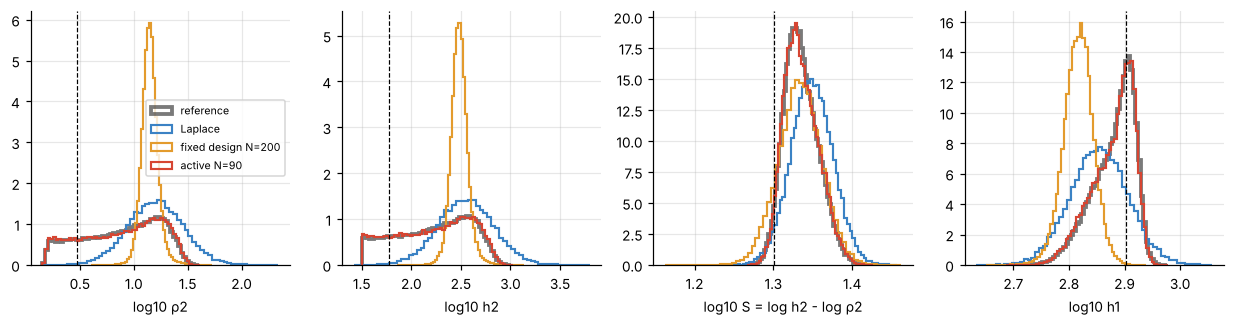

In [17]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
show = [("reference", REF["B"]), ("laplace", stB["laplace"]), ("lhs", stB["lhs200"][0]), ("active", stB["active"][0])]
labels_show = {"reference": "reference", "laplace": "Laplace", "lhs": "fixed design N=200", "active": f"active N={len(stB['active'][1])}"}
for i, (pi, nm) in enumerate([(1, "log10 ρ2"), (4, "log10 h2"), (None, "log10 S = log h2 - log ρ2"), (3, "log10 h1")]):
    for m, P in show:
        vals = P[:, 4] - P[:, 1] if pi is None else P[:, pi]
        axes[i].hist(vals, 60, density=True, histtype="step", lw=1.4 if m != "reference" else 2.5,
                     color=COL[m], alpha=0.6 if m == "reference" else 1, label=labels_show[m])
    axes[i].set_xlabel(nm)
    tv = truth_B[4] - truth_B[1] if pi is None else truth_B[pi]
    axes[i].axvline(tv, color="k", ls="--", lw=0.8)
axes[0].legend(fontsize=7)
savefig(fig, "08_case_B_marginals"); plt.show()

Active learning reproduces every marginal of case B, including the flat part of the ridge cut
off by the prior bound on $h_2$. Laplace is too narrow on that bound and shifted. The fixed
design is confidently wrong.

## 8. Field station pb30c

Same comparison on real data, for the supported 2-layer model (F2) and the over-parameterised
3-layer model (F3). Each reference uses about $10^6$ true-model calls.

In [18]:
t0 = time.time()
resF2, stF2, hF2 = run_case("F2", fixed_N=(50, 100, 200))
print(f"F2 done in {time.time() - t0:.0f} s"); t0 = time.time()
resF3, stF3, hF3 = run_case("F3", fixed_N=(100, 200, 400))
print(f"F3 done in {time.time() - t0:.0f} s")
resF = pd.concat([resF2, resF3]); resF.to_csv(f"{RES}/field_cost_accuracy.csv", index=False)
pd.concat([hF2, hF3]).to_csv(f"{RES}/active_learning_rounds_field.csv", index=False)
resF.round(3)

F2 done in 257 s


F3 done in 923 s


,case,method,seed,calls,W1,seconds
0,F2,laplace,0,1509,0.681,NaN
1,F2,lhs,0,50,7.054,NaN
2,F2,lhs,0,100,3.989,NaN
3,F2,lhs,0,200,2.154,NaN
4,F2,active,0,60,0.012,46.571
5,F2,active,1,70,0.026,56.099
6,F2,active,2,70,0.017,55.750
7,F2,da,0,59461,0.022,NaN
8,F2,reference,0,530011,0.014,NaN
0,F3,laplace,0,4781,0.637,NaN


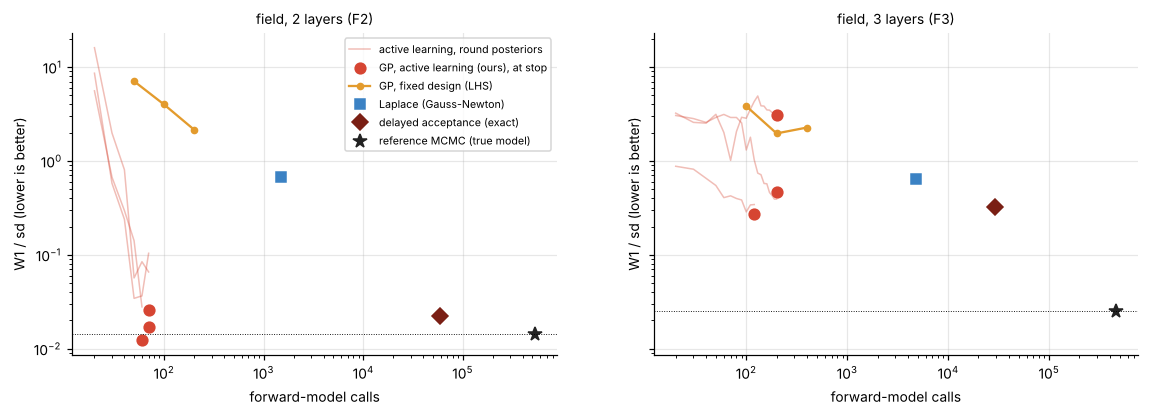

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8), sharey=True)
cost_plot(axes[0], resF2, hF2, "field, 2 layers (F2)"); cost_plot(axes[1], resF3, hF3, "field, 3 layers (F3)")
axes[0].legend(fontsize=7, loc="upper right")
savefig(fig, "09_cost_accuracy_field"); plt.show()

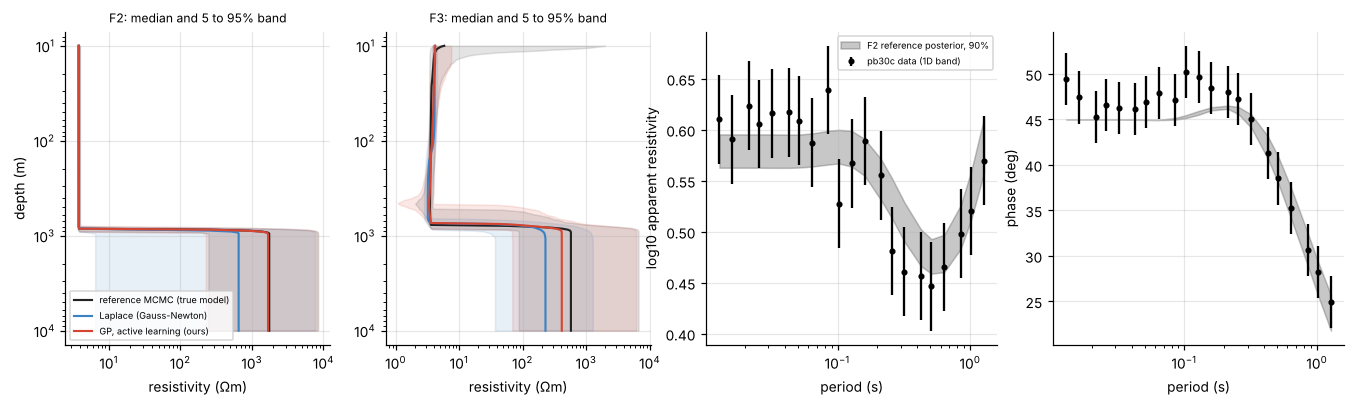

In [20]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.7), gridspec_kw=dict(width_ratios=[1, 1, 1.1, 1.1]))
zz = np.logspace(1, 4, 300)
for ax, key, st in [(axes[0], "F2", stF2), (axes[1], "F3", stF3)]:
    prob = CASES[key]
    for m, P in [("reference", REF[key]), ("laplace", st["laplace"]), ("active", st["active"][0])]:
        sub = P[np.random.default_rng(0).choice(len(P), 3000, replace=False)]
        sub = sub[prob.inside(sub)]
        q = np.percentile(np.log10(depth_profile(sub, prob.nlay, zz)), [5, 50, 95], axis=0)
        ax.fill_betweenx(zz, 10 ** q[0], 10 ** q[2], color=COL[m], alpha=0.12)
        ax.plot(10 ** q[1], zz, color=COL[m], lw=1.4, label=LAB[m])
    ax.set_xscale("log"); ax.set_yscale("log"); ax.invert_yaxis(); ax.set_xlabel("resistivity (Ωm)")
    ax.set_title(f"{key}: median and 5 to 95% band", fontsize=8)
axes[0].set_ylabel("depth (m)"); axes[0].legend(fontsize=6, loc="lower left")
probF = CASES["F2"]; T_ = 1 / probF.f; nF = len(probF.f)
pred = mt1d(REF["F2"][np.random.default_rng(1).choice(len(REF["F2"]), 400)], probF.f, 2)
for ax, sl, yl in [(axes[2], slice(0, nF), "log10 apparent resistivity"), (axes[3], slice(nF, 2 * nF), "phase (deg)")]:
    q = np.percentile(pred[:, sl], [5, 95], axis=0)
    ax.fill_between(T_, q[0], q[1], color=COL["reference"], alpha=0.25, label="F2 reference posterior, 90%")
    ax.errorbar(T_, probF.dobs[sl], yerr=probF.sig[sl], fmt="o", ms=3, color="k", label="pb30c data (1D band)")
    ax.set_xscale("log"); ax.set_xlabel("period (s)"); ax.set_ylabel(yl)
axes[2].legend(fontsize=6)
savefig(fig, "10_field_models"); plt.show()

**Reading the field results.**

* **F2 (the model the data support).** Active learning matches the reference with **60 to 70
  calls** for all three seeds (W1/sd 0.01 to 0.03, at the reference noise level). Laplace
  (0.68) and the fixed design (2.2 at 200 runs) do not. The posterior describes about 3.8 Ωm
  of conductive cover, about 860 m thick, over a resistive basement whose resistivity is only
  bounded from below (the wide band below 1 km): MT in this band sees the conductor, not the
  resistor. The 2-layer model fits within the error bars ($\chi^2/N = 0.65$) but cannot reach the
  short-period phases slightly above 45°, a hint of a more conductive layer inside the cover.
* **F3 (over-parameterised).** Here **every method falls short**, including active learning
  (W1/sd 0.27 to 3.1 after 120 to 200 runs). The posterior is broad and spread over a large
  part of the box, so there is no small region to concentrate runs in, and 200 runs are not
  enough to emulate the forward model over that much space. The stopping rule **did not fire**
  for two of the three seeds, which is the right signal: the method says it has not
  converged. Delayed acceptance is exact in principle, but its 3000-step chain had not mixed
  over the broad posterior (0.32).

So surrogates pay off when the data constrain the model and the posterior is small compared
with the prior. When the model has more freedom than the data can resolve, the cheap answer
is to simplify the model, not to emulate it better.

## 9. Summary

Numbers from this run:

In [21]:
summary = pd.concat([res_syn, resF]).round(3)
print(summary.to_string())
print("\nReference posteriors:")
for k in REF:
    print(f"  case {k}: {REF_CALLS[k]:,} calls, run-to-run W1/sd {REF_NOISE[k]:.3f}, mean {REF[k].mean(0).round(2)}, sd {REF[k].std(0).round(3)}")
print("\nEmulator calibration:\n", calib_table.to_string())
json.dump(dict(cost_accuracy=pd.concat([res_syn, resF]).to_dict("records"),
               reference={k: dict(calls=int(REF_CALLS[k]), noise=REF_NOISE[k], mean=REF[k].mean(0).tolist(), sd=REF[k].std(0).tolist()) for k in REF},
               calibration=calib_table.to_dict("records")),
          open(f"{RES}/summary.json", "w"), indent=1, default=float)

  case     method  seed   calls      W1  seconds
0    A    laplace     0     506   0.057      NaN
1    A        lhs     0      50  15.782      NaN
2    A        lhs     0     100   4.456      NaN
3    A        lhs     0     200   7.637      NaN
4    A        lhs     0     400   1.012      NaN
5    A     active     0      70   0.034  108.001
6    A     active     1      90   0.032  141.743
7    A     active     2      70   0.033  107.349
8    A         da     0   53007   0.025      NaN
9    A  reference     0  581693   0.006      NaN
0    B    laplace     0     597   0.547      NaN
1    B        lhs     0      50   6.755      NaN
2    B        lhs     0     100   3.668      NaN
3    B        lhs     0     200   1.075      NaN
4    B        lhs     0     400   1.219      NaN
5    B     active     0      90   0.028  143.789
6    B     active     1      80   0.057  135.236
7    B     active     2      90   0.019  132.395
8    B         da     0   46375   0.051      NaN
9    B  reference   

### What to take from this notebook

**What works**

* A PCA plus Gaussian-process emulator of the MT data, trained with **active learning** and a
  **stopping rule**, reproduces the full Bayesian posterior with **60 to 90 forward calls**
  in the three well-posed cases (two synthetic, one field), for every random seed, against
  about 550,000 calls for the reference MCMC.
* Where the training runs go matters more than how many there are. A space-filling design
  over the prior fails even with 400 runs, because the posterior fills about $10^{-8}$ of the
  box.
* A Gaussian (Laplace) approximation is fine for a well-resolved model (case A) but wrong for
  the equivalence ridge of a thin conductor (case B) and for the one-sided basement
  resistivity on the field data (F2).
* The emulator's own uncertainty, carried into the likelihood, is honest or slightly
  conservative, and it drives both the choice of new runs and the stopping rule.

**What it took to make it reliable**

* The samplers had to be started well. Both the true and the surrogate posteriors have local
  modes, and an ensemble sampler started at random can put every walker in the wrong one.
  Starting from a global scan plus the training runs with the best true misfit fixed it at
  no extra forward-model cost.
* A fixed run budget was unreliable across seeds. A stopping rule based on posterior change
  between rounds and on the data fit made every well-posed run succeed.

**Where it stops working**

* For an over-parameterised model with a broad posterior (F3), 200 runs were not enough for any
  method, and the stopping rule correctly refused to stop for two of three seeds.
* Delayed acceptance is exact but costs about 50,000 true calls here, and it needs a long
  enough chain to mix: it is a check, not a shortcut.

**Limits.** 1D forward model (the cost is counted, not felt); 3 to 5 parameters; one field
station; the 1D band chosen by a simple rule; three seeds per case.

### Next steps

* **Hamiltonian Monte Carlo on the surrogate.** The GP mean has analytic gradients, so HMC can
  run on the surrogate at almost no cost, which matters as the number of layers grows.
* **Joint inversion.** The same surrogate idea applies when MT is combined with another data
  set (for example seismic travel times through a Dix-type relation), where each forward model
  has its own cost.
* **Expensive forward models.** The real test is a 2D or 3D MT solver, where the forward calls
  counted here become hours of compute.
* **Better acquisition.** The criterion used here (posterior-weighted emulator variance) is
  simple. Criteria that target the expected change in the posterior itself may need fewer runs.